# Early-Season Predictiveness

For N = 1 to 81 games: R² of a team's win % and net rating over its first N games against its win % and net rating over the rest of the season (games N+1 to 82). Full 82-game seasons from 2000-01 through 2025-26; shortened seasons are excluded. Net rating uses Basketball-Reference's possession estimate from each game's box score. Bands are 95% bootstrap intervals over team-seasons.

Source: Basketball-Reference team game logs.

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.teams.net_rating import SHORTENED, first_n_above, game_logs, r_squared_by_games
from nba_analytics.teams.net_rating_plots import LABELS, plot_r2_by_games

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7

logs = game_logs(range(2001, 2027))
logs = logs[~logs["season"].isin(SHORTENED)]
curves = r_squared_by_games(logs, max_n=81, n_boot=500)

## First N with R² > 0.5, and the peak

In [2]:
peak = curves.loc[curves.groupby(["predictor", "target"])["r2"].idxmax(),
                  ["predictor", "target", "n", "r2"]]
(first_n_above(curves, 0.5)
 .merge(peak, on=["predictor", "target"])
 .replace({"predictor": LABELS, "target": LABELS})
 .rename(columns={"predictor": "First-N measure", "target": "Rest-of-season measure",
                  "first_n": "First N with R² > 0.5", "n": "Peak N", "r2": "Peak R²"})
 .round(3))

,First-N measure,Rest-of-season measure,First N with R² > 0.5,Peak N,Peak R²
0,Win %,Win %,22,51,0.544
1,Win %,Net rating,22,54,0.551
2,Net rating,Win %,17,50,0.569
3,Net rating,Net rating,15,54,0.580


## R² by games played

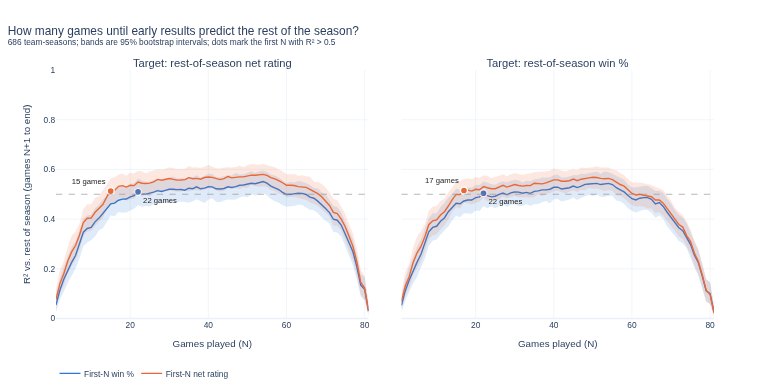

In [3]:
plot_r2_by_games(curves, threshold=0.5).show()

## R² at selected checkpoints

In [4]:
checkpoints = [5, 10, 15, 20, 25, 30, 41, 60]
(curves[curves["n"].isin(checkpoints)]
 .assign(pair=lambda d: d["predictor"].map(LABELS) + " → " + d["target"].map(LABELS))
 .pivot(index="n", columns="pair", values="r2").round(3)
 .rename_axis(index="Games played", columns=None))

,Net rating → Net rating,Net rating → Win %,Win % → Net rating,Win % → Win %
Games played,,,,
5,0.268,0.264,0.226,0.227
10,0.404,0.397,0.367,0.371
15,0.512,0.499,0.462,0.464
20,0.536,0.520,0.489,0.486
25,0.545,0.522,0.504,0.492
30,0.563,0.539,0.520,0.509
41,0.568,0.558,0.530,0.529
60,0.536,0.503,0.499,0.482
